# Project 1 Assessment — Housing in Brazil 🇧🇷

## Scenario

You work as a **junior data analyst** for an international real estate investment company. The company is considering entering the **Brazilian** housing market and has asked you to answer two questions:

1. **Are there regional differences in the Brazilian real estate market?** Which regions are the most and least expensive?
2. **In southern Brazil, is there a relationship between home size and price** — similar to what we saw in some Mexican states?

You have received **two raw CSV files** with listings of homes for sale. As in the Mexico project, the data is messy and must be cleaned before any analysis.

## How this assignment works

This is an **independent** assignment. It uses **only** the concepts from the four lessons of this project:

| Lesson | Topics |
|---|---|
| 1 — Organizing Tabular Data in Python | lists, dictionaries, `for` loops, DataFrames |
| 2 — Preparing Real Estate Data with pandas | `read_csv`, `info`, `dropna`, `str.replace`, `str.split`, `astype`, `drop`, `concat`, `to_csv` |
| 3 — Exploratory Data Analysis | `value_counts`, `describe`, histograms, boxplots, skewness, outliers, maps |
| 4 — Location or Size? | `groupby`, `agg`, bar charts, price per m², boolean masks, scatter plots, correlation |

* Each task tells you **what** to do — **you** write the code in the empty cell below it.
* **📚 Review** points to the lesson where you learned the concept.
* ✅ **Check cells** test your result automatically. Run them right after completing the task. A check tells you *whether* your result looks correct — not *how* to get it.
* ✍️ **Written questions:** double-click the answer cell and write your answer in full sentences. Use numbers from your results.
* **Charts** must always have axis labels (with units) and a title.
* Use the **variable names** given in the tasks — the checks depend on them.

## Suggested grading

| Part | Points |
|---|---:|
| Part 1 — Prepare the Data | 30 |
| Part 2 — Explore the Data | 20 |
| Part 3 — Regional Differences | 20 |
| Part 4 — Size and Price in Southern Brazil | 20 |
| Part 6 — Final Report | 10 |
| **Total** | **100** |
| Part 5 — Challenge (bonus) | +10 |

Good luck! 🚀

---
## Setup (run these two cells first — do not modify)

The first cell prepares the data files. If the files `brasil-real-estate-1.csv` and `brasil-real-estate-2.csv` exist, they are used.The second cell defines the `check()` function used by the ✅ check cells.

In [1]:

# ---------- Data setup: do not modify ----------
import os

import numpy as np
import pandas as pd

FILE_1 = "brasil-real-estate-1.csv"
FILE_2 = "brasil-real-estate-2.csv"

if os.path.exists(FILE_1) and os.path.exists(FILE_2):
    print("Original data files found. Using them.")
else:
    print("Data files not found. Please upload both CSV files.")


Original data files found. Using them.


In [2]:

# ---------- Check functions: do not modify ----------
_RAW1 = pd.read_csv(FILE_1)
_RAW2 = pd.read_csv(FILE_2)

_COLS = {"property_type", "state", "region", "lat", "lon", "area_m2", "price_usd"}
_REGIONS = {"North", "Northeast", "Central-West", "Southeast", "South"}


def _float(s):
    return pd.api.types.is_float_dtype(s)


def _near(a, b, tol=1e-6):
    return np.allclose(np.asarray(a, dtype=float), np.asarray(b, dtype=float), atol=tol)


_CHECKS = {
    1: (["pd", "plt"], [
        ("pandas imported as pd", lambda g: g["pd"].__name__ == "pandas"),
        ("matplotlib.pyplot imported as plt", lambda g: g["plt"].__name__ == "matplotlib.pyplot"),
    ]),

    2: (["df1"], [
        ("df1 is a DataFrame", lambda g: isinstance(g["df1"], pd.DataFrame)),
        ("df1 contains all rows and columns of file 1", lambda g: g["df1"].shape == _RAW1.shape),
    ]),

    4: (["df1"], [
        ("df1 has no missing values", lambda g: g["df1"].isnull().sum().sum() == 0),
        ("the correct number of rows was removed", lambda g: len(g["df1"]) == len(_RAW1.dropna())),
    ]),

    5: (["df1"], [
        ("df1 has columns 'lat' and 'lon'", lambda g: {"lat", "lon"} <= set(g["df1"].columns)),
        ("'lat' and 'lon' are float", lambda g: _float(g["df1"]["lat"]) and _float(g["df1"]["lon"])),
        ("latitudes are inside Brazil (not swapped with longitude)",
         lambda g: g["df1"]["lat"].between(-35, 6).all() and g["df1"]["lon"].between(-75, -30).all()),
    ]),

    6: (["df1"], [
        ("df1 has a 'state' column", lambda g: "state" in g["df1"].columns),
        ("state names contain no '|' and are not empty",
         lambda g: not g["df1"]["state"].str.contains("|", regex=False).any()
                   and (g["df1"]["state"].str.len() > 0).all()),
        ("'Brasil' is not used as a state name", lambda g: "Brasil" not in set(g["df1"]["state"])),
    ]),

    7: (["df1"], [
        ("'price_usd' is float", lambda g: _float(g["df1"]["price_usd"])),
        ("all prices are positive", lambda g: (g["df1"]["price_usd"] > 0).all()),
    ]),

    8: (["df1"], [
        ("df1 has exactly the required columns", lambda g: set(g["df1"].columns) == _COLS),
    ]),

    9: (["df2"], [
        ("df2 is a DataFrame", lambda g: isinstance(g["df2"], pd.DataFrame)),
        ("df2 contains all rows and columns of file 2", lambda g: g["df2"].shape == _RAW2.shape),
    ]),

    10: (["df2"], [
        ("df2 has a float 'price_usd' column",
         lambda g: "price_usd" in g["df2"].columns and _float(g["df2"]["price_usd"])),
        ("price_usd is correctly converted from reals",
         lambda g: "price_brl" not in g["df2"].columns
                   or _near(g["df2"]["price_usd"], g["df2"]["price_brl"] / 3.19, tol=0.01)),
    ]),

    11: (["df2"], [
        ("'price_brl' was removed", lambda g: "price_brl" not in g["df2"].columns),
        ("df2 has no missing values", lambda g: g["df2"].isnull().sum().sum() == 0),
        ("df2 has exactly the required columns", lambda g: set(g["df2"].columns) == _COLS),
    ]),

    12: (["df1", "df2"], [
        ("df1 and df2 have the same columns", lambda g: set(g["df1"].columns) == set(g["df2"].columns)),
        ("df1 and df2 have the same data types",
         lambda g: all(g["df1"][c].dtype == g["df2"][c].dtype for c in g["df1"].columns)),
    ]),

    13: (["df", "df1", "df2"], [
        ("df has all rows of df1 and df2", lambda g: len(g["df"]) == len(g["df1"]) + len(g["df2"])),
        ("df has exactly the required columns", lambda g: _COLS <= set(g["df"].columns)),
        ("df has a unique index (hint: ignore_index)", lambda g: g["df"].index.is_unique),
    ]),

    14: (["df"], [
        ("file brasil-real-estate-clean.csv exists",
         lambda g: os.path.exists("brasil-real-estate-clean.csv")),
        ("saved file has the same shape as df (no extra index column)",
         lambda g: pd.read_csv("brasil-real-estate-clean.csv").shape[0] == len(g["df"])
                   and set(pd.read_csv("brasil-real-estate-clean.csv").columns) <= set(g["df"].columns)),
    ]),

    16: (["region_counts", "region_share", "df"], [
        ("region_counts has one value per region", lambda g: set(g["region_counts"].index) == _REGIONS),
        ("region_counts adds up to the number of listings", lambda g: g["region_counts"].sum() == len(g["df"])),
        ("region_share is in percent (adds up to 100)", lambda g: abs(g["region_share"].sum() - 100) < 0.01),
    ]),

    17: (["top_states", "df"], [
        ("top_states has 10 states", lambda g: len(g["top_states"]) == 10),
        ("top_states contains the 10 largest counts, sorted",
         lambda g: list(g["top_states"].values) == list(g["df"]["state"].value_counts().head(10).values)),
    ]),

    18: (["summary_stats"], [
        ("summary_stats is a DataFrame", lambda g: isinstance(g["summary_stats"], pd.DataFrame)),
        ("summary_stats has columns area_m2 and price_usd",
         lambda g: list(g["summary_stats"].columns) == ["area_m2", "price_usd"]),
        ("summary_stats contains the median (50%)", lambda g: "50%" in g["summary_stats"].index),
    ]),

    21: (["skewness", "price_outliers", "df"], [
        ("skewness contains area_m2 and price_usd",
         lambda g: {"area_m2", "price_usd"} <= set(g["skewness"].index)),
        ("price_outliers is a DataFrame", lambda g: isinstance(g["price_outliers"], pd.DataFrame)),
        ("price_outliers has the correct number of rows (1.5 × IQR rule)",
         lambda g: len(g["price_outliers"]) == int((
             (g["df"]["price_usd"] < g["df"]["price_usd"].quantile(0.25)
              - 1.5 * (g["df"]["price_usd"].quantile(0.75) - g["df"]["price_usd"].quantile(0.25)))
             |
             (g["df"]["price_usd"] > g["df"]["price_usd"].quantile(0.75)
              + 1.5 * (g["df"]["price_usd"].quantile(0.75) - g["df"]["price_usd"].quantile(0.25)))
         ).sum())),
    ]),

    22: (["mean_price_by_region", "df"], [
        ("one value per region", lambda g: set(g["mean_price_by_region"].index) == _REGIONS),
        ("sorted from smallest to largest", lambda g: g["mean_price_by_region"].is_monotonic_increasing),
        ("values are the mean prices",
         lambda g: _near(g["mean_price_by_region"].sort_index(),
                         g["df"].groupby("region")["price_usd"].mean().sort_index(), tol=0.01)),
    ]),

    24: (["mean_area_by_region"], [
        ("one value per region", lambda g: set(g["mean_area_by_region"].index) == _REGIONS),
    ]),

    25: (["df"], [
        ("df has a 'price_per_m2' column", lambda g: "price_per_m2" in g["df"].columns),
        ("price_per_m2 = price_usd / area_m2",
         lambda g: _near(g["df"]["price_per_m2"], g["df"]["price_usd"] / g["df"]["area_m2"], tol=0.01)),
    ]),

    26: (["region_summary"], [
        ("region_summary has count, mean and median columns",
         lambda g: {"count", "mean", "median"} <= set(g["region_summary"].columns)),
        ("one row per region", lambda g: set(g["region_summary"].index) == _REGIONS),
        ("sorted by median, highest first", lambda g: g["region_summary"]["median"].is_monotonic_decreasing),
    ]),

    28: (["top_states_ppm", "df"], [
        ("top_states_ppm has 5 states", lambda g: len(g["top_states_ppm"]) == 5),
        ("sorted from highest to lowest", lambda g: g["top_states_ppm"].is_monotonic_decreasing),
        ("only states with at least 30 listings",
         lambda g: all(g["df"]["state"].value_counts()[s] >= 30 for s in g["top_states_ppm"].index)),
    ]),

    29: (["df_south", "df"], [
        ("df_south is a DataFrame (not a mask!)", lambda g: isinstance(g["df_south"], pd.DataFrame)),
        ("all rows are in the South region", lambda g: (g["df_south"]["region"] == "South").all()),
        ("all southern homes are included",
         lambda g: len(g["df_south"]) == (g["df"]["region"] == "South").sum()),
    ]),

    30: (["homes_by_state", "df_south"], [
        ("homes_by_state has the 3 southern states", lambda g: len(g["homes_by_state"]) == 3),
        ("counts add up to the number of southern homes",
         lambda g: g["homes_by_state"].sum() == len(g["df_south"])),
    ]),

    32: (["corr_brazil", "corr_south", "df", "df_south"], [
        ("corr_brazil is correct",
         lambda g: abs(g["corr_brazil"] - g["df"]["area_m2"].corr(g["df"]["price_usd"])) < 1e-6),
        ("corr_south is correct",
         lambda g: abs(g["corr_south"] - g["df_south"]["area_m2"].corr(g["df_south"]["price_usd"])) < 1e-6),
    ]),

    33: (["south_states_corr", "df_south"], [
        ("south_states_corr is a dictionary", lambda g: isinstance(g["south_states_corr"], dict)),
        ("keys are the 3 southern states",
         lambda g: set(g["south_states_corr"]) == set(g["df_south"]["state"].unique())),
        ("values are the correct correlation coefficients",
         lambda g: all(abs(v - g["df_south"][g["df_south"]["state"] == k]["area_m2"]
                           .corr(g["df_south"][g["df_south"]["state"] == k]["price_usd"])) < 1e-6
                     for k, v in g["south_states_corr"].items())),
    ]),

    35: (["corr_by_state", "df"], [
        ("only states with at least 30 listings",
         lambda g: all(g["df"]["state"].value_counts()[s] >= 30 for s in g["corr_by_state"].index)),
        ("all states with at least 30 listings are included",
         lambda g: len(g["corr_by_state"]) == (g["df"]["state"].value_counts() >= 30).sum()),
        ("sorted from highest to lowest", lambda g: g["corr_by_state"].is_monotonic_decreasing),
    ]),
}


def check(task):
    """Check your result for a task, e.g. check(4)."""
    g = globals()
    required, tests = _CHECKS[task]

    missing = [name for name in required if name not in g]
    if missing:
        print(f"❌ Task {task}: variable(s) {', '.join(missing)} not found. "
              "Complete the task and run its cell first.")
        return

    passed = 0
    for description, test in tests:
        try:
            ok = bool(test(g))
        except Exception:
            ok = False
        print(("✅ " if ok else "❌ ") + description)
        passed += ok

    if passed == len(tests):
        print(f"🎉 Task {task}: all checks passed!")
    else:
        print(f"Task {task}: {passed}/{len(tests)} checks passed. Fix the ❌ items and run the check again.")


print("Check functions ready. Use check(<task number>) after each task.")


Check functions ready. Use check(<task number>) after each task.


---
# Part 1 — Prepare the Data (30 points)

### Task 1 — Import libraries

Import **pandas** as `pd` and **matplotlib.pyplot** as `plt` (and **numpy** as `np` if you need it).

📚 Review: Lesson 2, Setup; Lesson 3, Setup.

In [3]:
# Write your code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

✅ **Check your work** — run the cell below.

In [4]:
check(1)

✅ pandas imported as pd
✅ matplotlib.pyplot imported as plt
🎉 Task 1: all checks passed!


## 1.1 File 1: `brasil-real-estate-1.csv`

### Task 2 — Import file 1

Read `data/brasil-real-estate-1.csv` into a DataFrame named **`df1`**.

📚 Review: Lesson 2, Exercise 1.

In [5]:
# Write your code here
df1 = pd.read_csv('brasil-real-estate-1.csv')

✅ **Check your work** — run the cell below.

In [6]:
check(2)

✅ df1 is a DataFrame
✅ df1 contains all rows and columns of file 1
🎉 Task 2: all checks passed!


### Task 3 — Inspect `df1`

Inspect `df1` with `.shape`, `.info()`, `.head()`, and count the missing values in each column.

📚 Review: Lesson 2, Exercise 2 and Practice 1.

In [7]:
# Write your code here
df1.shape

(12834, 6)

In [8]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 12834 entries, 0 to 12833
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   property_type            12834 non-null  str    
 1   place_with_parent_names  12834 non-null  str    
 2   region                   12834 non-null  str    
 3   lat-lon                  11551 non-null  str    
 4   area_m2                  12834 non-null  float64
 5   price_usd                12834 non-null  str    
dtypes: float64(1), str(5)
memory usage: 601.7 KB


In [9]:
df1.head()

,property_type,place_with_parent_names,region,lat-lon,area_m2,price_usd
0,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.6443051,-35.7088142",110.0,"$187,230.85"
1,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.6430934,-35.70484",65.0,"$81,133.37"
2,house,|Brasil|Alagoas|Maceió|,Northeast,"-9.6227033,-35.7297953",211.0,"$154,465.45"
3,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.622837,-35.719556",99.0,"$146,013.20"
4,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.654955,-35.700227",55.0,"$101,416.71"


In [10]:
df1.isnull().sum()

property_type                 0
place_with_parent_names       0
region                        0
lat-lon                    1283
area_m2                       0
price_usd                     0
dtype: int64

✍️ **Question 1:** List **every problem** you see in `df1` that must be fixed before analysis. For each problem, name the pandas tool you will use to fix it.

✍️ **Your answer:** 

The problems that I found in `df1`:

1. The column `lat-lon` has 1283 missing values. I'll remove these rows using method `dropna`
2. A Latitude and a longitude are together in one column. I will split them with `str.split` and change them to numbers with `astype(float)`.
3. There is no the `state` column. The state is inside `place_with_parent_names`, so I will take it out using `str.split` method
4. `price_usd` is a string with a dollar sign and commas, so I can't do math with it. I will remove these symbols with `str.replace` and then use `astype(float)`.
5. After that, `lat-lon` and `place_with_parent_names` are not needed anymore, so I will remove them with `drop` method

### Task 4 — Remove missing values

Drop all rows with `NaN` values from `df1`. Print how many rows were removed.

📚 Review: Lesson 2, Exercise 3.

In [11]:
rows_before = len(df1)
df1 = df1.dropna()
print('Rows removed:', rows_before - len(df1))

Rows removed: 1283


✅ **Check your work** — run the cell below.

In [12]:
check(4)

✅ df1 has no missing values
✅ the correct number of rows was removed
🎉 Task 4: all checks passed!


### Task 5 — Create `lat` and `lon`

Use the `lat-lon` column to create two new columns, **`lat`** and **`lon`**, with data type **float**.

📚 Review: Lesson 2, Exercise 9.

In [13]:
# Write your code here
df1[['lat', 'lon']] = df1['lat-lon'].str.split(',', expand=True).astype(float)
df1.head()

,property_type,place_with_parent_names,region,lat-lon,area_m2,price_usd,lat,lon
0,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.6443051,-35.7088142",110.0,"$187,230.85",-9.644305,-35.708814
1,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.6430934,-35.70484",65.0,"$81,133.37",-9.643093,-35.704840
2,house,|Brasil|Alagoas|Maceió|,Northeast,"-9.6227033,-35.7297953",211.0,"$154,465.45",-9.622703,-35.729795
3,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.622837,-35.719556",99.0,"$146,013.20",-9.622837,-35.719556
4,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.654955,-35.700227",55.0,"$101,416.71",-9.654955,-35.700227


✅ **Check your work** — run the cell below.

In [14]:
check(5)

✅ df1 has columns 'lat' and 'lon'
✅ 'lat' and 'lon' are float
✅ latitudes are inside Brazil (not swapped with longitude)
🎉 Task 5: all checks passed!


### Task 6 — Create `state`

Use `place_with_parent_names` to create a **`state`** column. Look carefully at the values first: the state always comes **right after `|Brasil|`**.

⚠️ This data is similar — but not identical — to the Mexico data. Check your result with `.head()` or `.value_counts()` before moving on.

📚 Review: Lesson 2, Exercise 10.

In [15]:
# Write your code here
df1['state'] = df1['place_with_parent_names'].str.split('|', expand=True)[2]
df1['state'].value_counts()

state
Minas Gerais          2680
Paraná                2544
Bahia                 2045
Ceará                 1574
Distrito Federal       732
Espírito Santo         555
Goiás                  555
Pará                   299
Paraíba                250
Maranhão               101
Pernambuco              88
Mato Grosso             86
Alagoas                 24
Mato Grosso do Sul      14
Amazonas                 3
Amapá                    1
Name: count, dtype: int64

✅ **Check your work** — run the cell below.

In [16]:
check(6)

✅ df1 has a 'state' column
✅ state names contain no '|' and are not empty
✅ 'Brasil' is not used as a state name
🎉 Task 6: all checks passed!


### Task 7 — Convert `price_usd` to numbers

Transform `price_usd` so that all values are **floats** instead of strings.

📚 Review: Lesson 2, Exercise 4.

In [17]:
# Write your code here
df1['price_usd'] = (df1['price_usd'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float))

In [18]:
df1['price_usd'].dtype

dtype('float64')

✅ **Check your work** — run the cell below.

In [19]:
check(7)

✅ 'price_usd' is float
✅ all prices are positive
🎉 Task 7: all checks passed!


### Task 8 — Remove unnecessary columns

Drop the columns `lat-lon` and `place_with_parent_names` from `df1`. Then run `.info()` to confirm the result.

📚 Review: Lesson 2, Exercise 7.

In [20]:
# Write your code here
df1 = df1.drop(columns=['lat-lon', 'place_with_parent_names'])

In [21]:
df1.head()

,property_type,region,area_m2,price_usd,lat,lon,state
0,apartment,Northeast,110.0,187230.85,-9.644305,-35.708814,Alagoas
1,apartment,Northeast,65.0,81133.37,-9.643093,-35.704840,Alagoas
2,house,Northeast,211.0,154465.45,-9.622703,-35.729795,Alagoas
3,apartment,Northeast,99.0,146013.20,-9.622837,-35.719556,Alagoas
4,apartment,Northeast,55.0,101416.71,-9.654955,-35.700227,Alagoas


✅ **Check your work** — run the cell below.

In [22]:
check(8)

✅ df1 has exactly the required columns
🎉 Task 8: all checks passed!


## 1.2 File 2: `brasil-real-estate-2.csv`

### Task 9 — Import and inspect file 2

Read `data/brasil-real-estate-2.csv` into a DataFrame named **`df2`**. Inspect it with `.info()`, `.head()`, and the number of missing values per column.

📚 Review: Lesson 2, Exercises 1–2.

In [23]:
# Write your code here
df2 = pd.read_csv('brasil-real-estate-2.csv')
df2.info()
print(df2.isnull().sum())
df2.head()

<class 'pandas.DataFrame'>
RangeIndex: 12833 entries, 0 to 12832
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  12833 non-null  str    
 1   state          12833 non-null  str    
 2   region         12833 non-null  str    
 3   lat            12833 non-null  float64
 4   lon            12833 non-null  float64
 5   area_m2        11293 non-null  float64
 6   price_brl      12833 non-null  float64
dtypes: float64(4), str(3)
memory usage: 701.9 KB
property_type       0
state               0
region              0
lat                 0
lon                 0
area_m2          1540
price_brl           0
dtype: int64


,property_type,state,region,lat,lon,area_m2,price_brl
0,apartment,Pernambuco,Northeast,-8.134204,-34.906326,72.0,414222.98
1,apartment,Pernambuco,Northeast,-8.126664,-34.903924,136.0,848408.53
2,apartment,Pernambuco,Northeast,-8.125550,-34.907601,75.0,299438.28
3,apartment,Pernambuco,Northeast,-8.120249,-34.895920,187.0,848408.53
4,apartment,Pernambuco,Northeast,-8.142666,-34.906906,80.0,464129.36


✅ **Check your work** — run the cell below.

In [24]:
check(9)

✅ df2 is a DataFrame
✅ df2 contains all rows and columns of file 2
🎉 Task 9: all checks passed!


✍️ **Question 2:** How is `df2` **similar** to `df1`, and how is it **different**? Which problem from `df1` does **not** appear in `df2`, and which **new** problem does?

✍️ **Your answer:** *(double-click this cell to write your answer)*

**Similar:** both files have `property_type`, `region` and `area_m2`, and both are listings of homes for sale in Brazil from the same years

**Different:** in `df2` the coordinates are already in two separated float columns (`lat`, `lon`), there is already a `state` column, and the price already is a num. The problems with `lat-lon`, with the state hidden in `place_with_parent_names` and with the price stored as text do not appear in `df2`

**New problems:** the price is in Brazilian reals (`price_brl`), not in dollars, so I need to convert it. Also missing values are  in `area_m2` (1,540 rows) and not in the coordinates

### Task 10 — Convert reals to dollars

Create a new column **`price_usd`** in `df2` from `price_brl`. When this data was collected (2015–2016), **1 US dollar cost 3.19 Brazilian reals**.

📚 Review: Lesson 2, Exercise 6.

In [25]:
# Write your code here
df2['price_usd'] = df2['price_brl'] / 3.19
df2.head()

,property_type,state,region,lat,lon,area_m2,price_brl,price_usd
0,apartment,Pernambuco,Northeast,-8.134204,-34.906326,72.0,414222.98,129850.463950
1,apartment,Pernambuco,Northeast,-8.126664,-34.903924,136.0,848408.53,265958.786834
2,apartment,Pernambuco,Northeast,-8.125550,-34.907601,75.0,299438.28,93867.799373
3,apartment,Pernambuco,Northeast,-8.120249,-34.895920,187.0,848408.53,265958.786834
4,apartment,Pernambuco,Northeast,-8.142666,-34.906906,80.0,464129.36,145495.097179


✅ **Check your work** — run the cell below.

In [26]:
check(10)

✅ df2 has a float 'price_usd' column
✅ price_usd is correctly converted from reals
🎉 Task 10: all checks passed!


### Task 11 — Clean `df2`

Drop the `price_brl` column **and** all rows with `NaN` values from `df2`.

📚 Review: Lesson 2, Exercises 5 and 7.

In [27]:
# Write your code here
df2= df2.drop(columns='price_brl')
df2 = df2.dropna()
df2.info()

<class 'pandas.DataFrame'>
Index: 11293 entries, 0 to 12832
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  11293 non-null  str    
 1   state          11293 non-null  str    
 2   region         11293 non-null  str    
 3   lat            11293 non-null  float64
 4   lon            11293 non-null  float64
 5   area_m2        11293 non-null  float64
 6   price_usd      11293 non-null  float64
dtypes: float64(4), str(3)
memory usage: 705.8 KB


✅ **Check your work** — run the cell below.

In [28]:
check(11)

✅ 'price_brl' was removed
✅ df2 has no missing values
✅ df2 has exactly the required columns
🎉 Task 11: all checks passed!


## 1.3 Combine and save

### Task 12 — Check consistency

Before combining, show that `df1` and `df2` have the **same column names** and the **same data types** (for example, by printing the sorted column names and a table of `dtypes` side by side).

📚 Review: Lesson 2, Section 6.

In [29]:
# Write your code here
print(sorted(df1.columns))
print(sorted(df2.columns))
pd.concat([df1.dtypes, df2.dtypes], axis=1, keys=['df1', 'df2'])

['area_m2', 'lat', 'lon', 'price_usd', 'property_type', 'region', 'state']
['area_m2', 'lat', 'lon', 'price_usd', 'property_type', 'region', 'state']


,df1,df2
property_type,str,str
region,str,str
area_m2,float64,float64
price_usd,float64,float64
lat,float64,float64
lon,float64,float64
state,str,str


✅ **Check your work** — run the cell below.

In [30]:
check(12)

✅ df1 and df2 have the same columns
✅ df1 and df2 have the same data types
🎉 Task 12: all checks passed!


### Task 13 — Concatenate

Combine `df1` and `df2` into one DataFrame named **`df`** with a fresh index. Print its shape.

📚 Review: Lesson 2, Exercise 11.

In [31]:
# Write your code here
df = pd.concat([df1, df2], ignore_index=True)
print(df.shape)

(22844, 7)


✅ **Check your work** — run the cell below.

In [32]:
check(13)

✅ df has all rows of df1 and df2
✅ df has exactly the required columns
✅ df has a unique index (hint: ignore_index)
🎉 Task 13: all checks passed!


## Task 14 — Save the clean data

Save `df` to **`brasil-real-estate-clean.csv`** without the index. Read the file back and print its shape to verify.

📚 Review: Lesson 2, Exercise 12.

In [33]:
# Write your code here
df.to_csv('brasil-real-estate-clean.csv', index=False)
df_saved = pd.read_csv('brasil-real-estate-clean.csv')
print(df_saved.shape)

(22844, 7)


✅ **Check your work** — run the cell below.

In [34]:
check(14)

✅ file brasil-real-estate-clean.csv exists
✅ saved file has the same shape as df (no extra index column)
🎉 Task 14: all checks passed!


---
# Part 2 — Explore the Data (20 points)

## 2.1 Location

### Task 15 — Where are the properties?

Create a scatter plot of the property locations: **longitude** on the x-axis, **latitude** on the y-axis. Use small, semi-transparent dots. Label the axes and use the title `"Location of Properties in Brazil"`.

📚 Review: Lesson 3, Exercise 2.

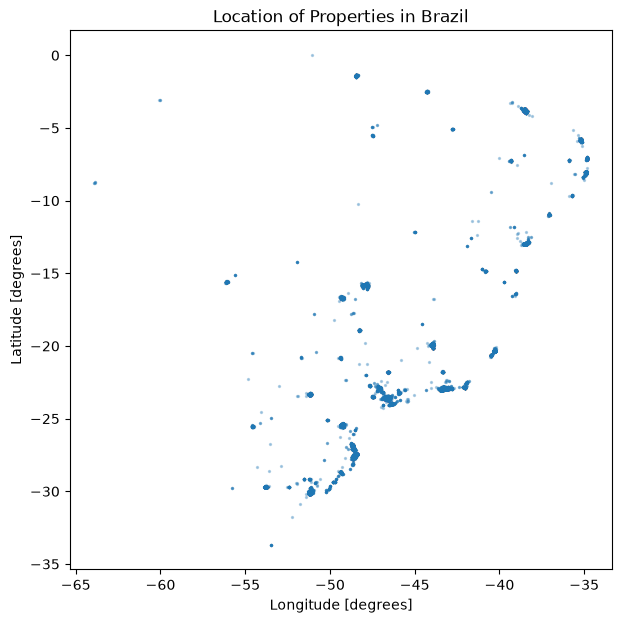

In [35]:
# Write your code here
plt.figure(figsize=(7, 7))
plt.scatter(df['lon'], df['lat'], s=2, alpha=0.3)
plt.xlabel('Longitude [degrees]')
plt.ylabel('Latitude [degrees]')
plt.title('Location of Properties in Brazil')
plt.show()

⭐ **Optional:** Create an **interactive map** with `plotly.express` (`px.scatter_map`), centered on Brazil (`{"lat": -14.2, "lon": -51.9}`), with `zoom=3` and the price shown when hovering. *(Requires internet access.)*

📚 Review: Lesson 3, Exercise 3.

In [36]:
# Write your code here
import plotly.express as px

fig = px.scatter_map(
    df,
    lat='lat',
    lon='lon',
    center={'lat': -14.2, 'lon': -51.9},
    zoom=3,
    hover_data=['price_usd'],
    width=700,
    height=600,
)
fig.show()

✍️ **Question 3:** Are the properties spread evenly across Brazil? Where are they concentrated? What might explain this pattern?

✍️ **Your answer:** 

No, they are not spread evenly. Most of the points are on the east coast and in the South and Southeast, around big cities like Sao Paulo, Rio de Janeiro, Belo Horizonte, Curitiba and Porto Alegre, and in some cities of the Northeast like Salvador, Fortaleza and Recife. The interior and the Amazon area in the north and west are almost empty.

I think the main reason is that most people in Brazil live in big cities close to the coast, so this is where most homes are bought, sold and listed online. The North region has only 309 listings (1.4% of the data), so we know very little about it.

## 2.2 Categorical data

### Task 16 — Listings per region

1. Create a Series **`region_counts`** with the number of listings in each region.
2. Create a Series **`region_share`** with the **percentage** of listings in each region.
3. Show `region_counts` as a bar chart with labels and a title.

📚 Review: Lesson 3, Exercises 4–6.

region
Southeast       8533
South           7821
Northeast       4794
Central-West    1387
North            309
Name: count, dtype: int64
region
Southeast       37.4
South           34.2
Northeast       21.0
Central-West     6.1
North            1.4
Name: proportion, dtype: float64


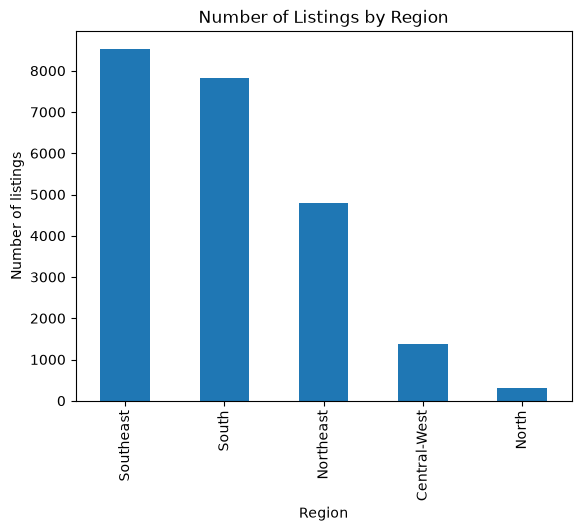

In [37]:
# Write your code here
region_counts = df['region'].value_counts()
region_share = df['region'].value_counts(normalize=True) * 100
print(region_counts)
print(region_share.round(1))

region_counts.plot(kind='bar')
plt.xlabel('Region')
plt.ylabel('Number of listings')
plt.title('Number of Listings by Region')
plt.show()

✅ **Check your work** — run the cell below.

In [38]:
check(16)

✅ region_counts has one value per region
✅ region_counts adds up to the number of listings
✅ region_share is in percent (adds up to 100)
🎉 Task 16: all checks passed!


### Task 17 — Top 10 states

Create a Series **`top_states`** with the 10 states that have the most listings.

📚 Review: Lesson 3, Exercise 4.

In [39]:
# Write your code here
top_states = df['state'].value_counts().head(10)
top_states

state
Minas Gerais         2680
São Paulo            2656
Rio Grande do Sul    2643
Rio de Janeiro       2642
Santa Catarina       2634
Paraná               2544
Bahia                2045
Ceará                1574
Distrito Federal      732
Espírito Santo        555
Name: count, dtype: int64

✅ **Check your work** — run the cell below.

In [40]:
check(17)

✅ top_states has 10 states
✅ top_states contains the 10 largest counts, sorted
🎉 Task 17: all checks passed!


## 2.3 Numerical data

### Task 18 — Summary statistics

Create a DataFrame **`summary_stats`** with the summary statistics of `area_m2` and `price_usd`.

📚 Review: Lesson 3, Exercise 7.

In [41]:
# Write your code here
summary_stats = df[['area_m2', 'price_usd']].describe()
summary_stats

,area_m2,price_usd
count,22844.000000,22844.000000
mean,115.020224,194987.315480
std,47.742932,103617.682978
min,53.000000,74892.340000
25%,76.000000,113898.770000
50%,103.000000,165697.555000
75%,142.000000,246900.880878
max,252.000000,525659.717868


✅ **Check your work** — run the cell below.

In [42]:
check(18)

✅ summary_stats is a DataFrame
✅ summary_stats has columns area_m2 and price_usd
✅ summary_stats contains the median (50%)
🎉 Task 18: all checks passed!


✍️ **Question 4:** Compare the **mean** and **median** of `price_usd`. Which is larger? What does that tell you about the distribution? Which value would you report as the "typical" home price, and why?

✍️ **Your answer:** 


The mean price is **$194,987** and the median is **$165,698**, so the mean is about $29,000 higher.

This means the distribution is skewed to the right. Most homes are cheaper, but a smaller group of expensive homes pulls the mean up.

I would report the **median** as the typical home price, because it is not affected so much by the expensive homes and shows better what a normal home costs.

### Task 19 — Histogram of prices

Create a histogram of `price_usd` with a suitable number of bins. Add **vertical lines** for the mean and the median, and a legend. Label the x-axis `"Price [USD]"`, the y-axis `"Frequency"`, and use the title `"Distribution of Home Prices"`.

📚 Review: Lesson 3, Exercises 8 and 10.

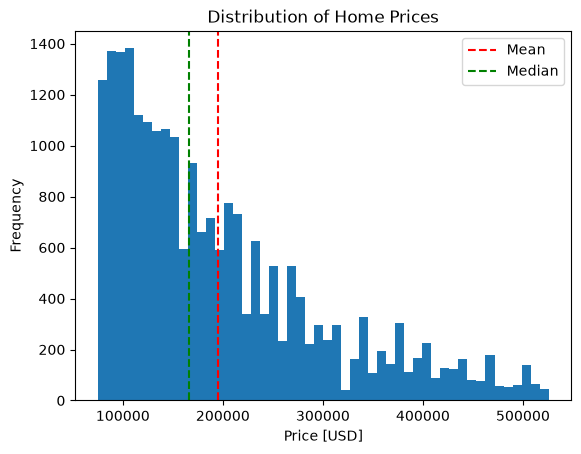

In [43]:
# Write your code here
mean_price = df['price_usd'].mean()
median_price = df['price_usd'].median()

plt.hist(df['price_usd'], bins=50)
plt.axvline(mean_price, color='red', linestyle='--', label='Mean')
plt.axvline(median_price, color='green', linestyle='--', label='Median')
plt.xlabel('Price [USD]')
plt.ylabel('Frequency')
plt.title('Distribution of Home Prices')
plt.legend()
plt.show()

### Task 20 — Boxplot of home sizes

Create a **horizontal** boxplot of `area_m2`. Label the x-axis `"Area [sq meters]"` and use the title `"Distribution of Home Sizes"`.

📚 Review: Lesson 3, Exercise 9.

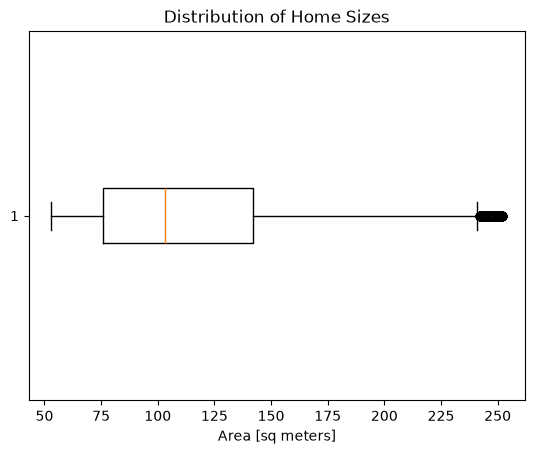

In [44]:
# Write your code here
plt.boxplot(df['area_m2'], orientation='horizontal')
plt.xlabel('Area [sq meters]')
plt.title('Distribution of Home Sizes')
plt.show()

### Task 21 — Skewness and outliers

1. Create a Series **`skewness`** with the skewness of `area_m2` and `price_usd`.
2. Using the **1.5 × IQR rule**, create a DataFrame **`price_outliers`** with all listings whose price is an outlier. Print how many outliers there are and what percentage of the data they represent.

📚 Review: Lesson 3, Exercises 11–12.

In [45]:
# Write your code here
skewness = df[['area_m2', 'price_usd']].skew()
print(skewness)

q1 = df['price_usd'].quantile(0.25)
q3 = df['price_usd'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

price_outliers = df[(df['price_usd'] < lower) | (df['price_usd'] > upper)]
print('Number of outliers:', len(price_outliers))
print('Share of all listings:', round(len(price_outliers) / len(df) * 100, 2), '%')

area_m2      0.929603
price_usd    1.131243
dtype: float64
Number of outliers: 743
Share of all listings: 3.25 %


✅ **Check your work** — run the cell below.

In [46]:
check(21)

✅ skewness contains area_m2 and price_usd
✅ price_outliers is a DataFrame
✅ price_outliers has the correct number of rows (1.5 × IQR rule)
🎉 Task 21: all checks passed!


✍️ **Question 5:** Which variable is more skewed? Should the price outliers be **removed** before analysis? Give one argument for and one against.

✍️ **Your answer:**

`price_usd` is more skewed (**1.13**) than `area_m2` (**0.93**). With the 1.5 * IQR rule there are **743** price outliers, which is **3.25%** of all listings.

**For removing them:** these expensive homes pull the mean up and can change the correlation, so the results for a normal home would be cleaner without them.

**Against removing them:** they are not mistakes. The most expensive home costs about $525700, which is realistic for a big apartment in a big city. If we remove them, we lose the expensive part of the market, and this part can be important for an investment company.

I would keep them and use the median, because the median is not affected much by outliers.

---
# Part 3 — Research Question 1: Regional Differences (20 points)

### Task 22 — Mean price by region

Create a Series **`mean_price_by_region`** with the mean home price in each region, sorted from **smallest to largest**.

📚 Review: Lesson 4, Exercise 2.

In [47]:
# Write your code here
mean_price_by_region = df.groupby('region')['price_usd'].mean().sort_values()
mean_price_by_region

region
Central-West    178596.283663
North           181308.958207
Northeast       185422.985441
South           189012.345265
Southeast       208996.762778
Name: price_usd, dtype: float64

✅ **Check your work** — run the cell below.

In [48]:
check(22)

✅ one value per region
✅ sorted from smallest to largest
✅ values are the mean prices
🎉 Task 22: all checks passed!


### Task 23 — Bar chart of mean price by region

Use `mean_price_by_region` to create a bar chart with **pandas**. Label the x-axis `"Region"`, the y-axis `"Mean Price [USD]"`, and use the title `"Mean Home Price by Region"`.

📚 Review: Lesson 4, Exercise 3.

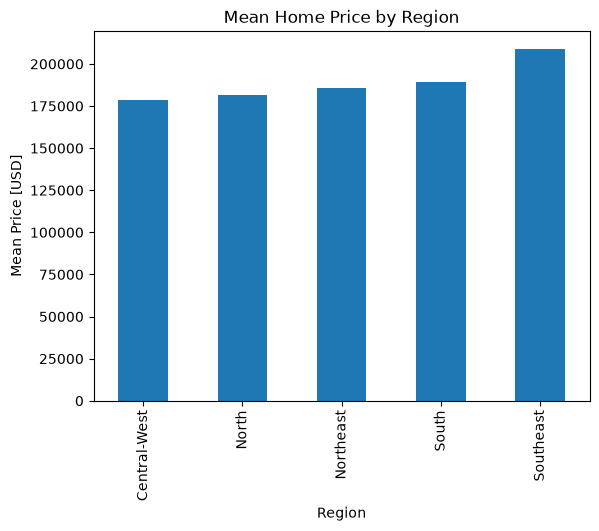

In [49]:
# Write your code here
mean_price_by_region.plot(kind='bar')
plt.xlabel('Region')
plt.ylabel('Mean Price [USD]')
plt.title('Mean Home Price by Region')
plt.show()

### Task 24 — Could size explain the differences?

In Mexico, we learned that differences in total price can be caused by differences in **home size**. Create a Series **`mean_area_by_region`** with the mean `area_m2` of each region (sorted).

📚 Review: Lesson 4, Exercise 4.

In [50]:
# Write your code here
mean_area_by_region = df.groupby('region')['area_m2'].mean().sort_values()
mean_area_by_region

region
Southeast       111.846713
South           115.731492
North           115.886731
Central-West    116.139149
Northeast       119.128911
Name: area_m2, dtype: float64

✅ **Check your work** — run the cell below.

In [51]:
check(24)

✅ one value per region
🎉 Task 24: all checks passed!


### Task 25 — Price per square meter

Add a column **`price_per_m2`** to `df`.

📚 Review: Lesson 4, Exercise 5.

In [52]:
# Write your code here
df['price_per_m2'] = df['price_usd']/ df['area_m2']
df.head()

,property_type,region,area_m2,price_usd,lat,lon,state,price_per_m2
0,apartment,Northeast,110.0,187230.85,-9.644305,-35.708814,Alagoas,1702.098636
1,apartment,Northeast,65.0,81133.37,-9.643093,-35.704840,Alagoas,1248.205692
2,house,Northeast,211.0,154465.45,-9.622703,-35.729795,Alagoas,732.063744
3,apartment,Northeast,99.0,146013.20,-9.622837,-35.719556,Alagoas,1474.880808
4,apartment,Northeast,55.0,101416.71,-9.654955,-35.700227,Alagoas,1843.940182


✅ **Check your work** — run the cell below.

In [53]:
check(25)

✅ df has a 'price_per_m2' column
✅ price_per_m2 = price_usd / area_m2
🎉 Task 25: all checks passed!


### Task 26 — A reliable regional comparison

Create a DataFrame **`region_summary`** with the **count**, **mean**, and **median** of `price_per_m2` for each region, sorted by the **median** from highest to lowest.

📚 Review: Lesson 4, Exercise 7.

In [54]:
# Write your code here
region_summary = (df.groupby('region')['price_per_m2'].agg(['count', 'mean', 'median']).sort_values('median', ascending=False))
region_summary

,count,mean,median
region,,,
Southeast,8533,1958.288815,1733.618968
North,309,1613.629152,1698.946556
South,7821,1687.930295,1560.006515
Northeast,4794,1600.886068,1533.726735
Central-West,1387,1602.232486,1498.668026


✅ **Check your work** — run the cell below.

In [55]:
check(26)

✅ region_summary has count, mean and median columns
✅ one row per region
✅ sorted by median, highest first
🎉 Task 26: all checks passed!


### Task 27 — Bar chart of price per m² by region

Create a bar chart of the **median** price per m² by region (highest first). Label the axes (with units) and add a title.

📚 Review: Lesson 4, Exercise 6.

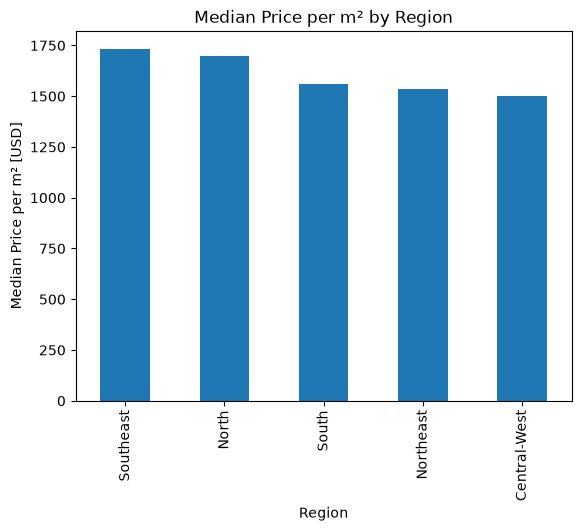

In [56]:
# Write your code here
region_summary['median'].plot(kind='bar')
plt.xlabel('Region')
plt.ylabel('Median Price per m² [USD]')
plt.title('Median Price per m² by Region')
plt.show()

### Task 28 — Most expensive states

Create a Series **`top_states_ppm`** with the **5 states** with the highest **median** price per m², considering only states with **at least 30 listings**.

📚 Review: Lesson 3, Mini Project Step 5.

In [57]:
# Write your code here
state_counts = df['state'].value_counts()
big_states = state_counts[state_counts >= 30].index

top_states_ppm = (df[df['state'].isin(big_states)].groupby('state')['price_per_m2'].median().sort_values(ascending=False).head(5))
top_states_ppm

state
Rio de Janeiro    1980.993510
São Paulo         1834.147057
Pernambuco        1809.077139
Santa Catarina    1787.008900
Pará              1718.927288
Name: price_per_m2, dtype: float64

✅ **Check your work** — run the cell below.

In [58]:
check(28)

✅ top_states_ppm has 5 states
✅ sorted from highest to lowest
✅ only states with at least 30 listings
🎉 Task 28: all checks passed!


✍️ **Question 6:** Answer **Research Question 1**. Which region is the most expensive and which the least expensive? Does the ranking change between **mean total price** and **median price per m²**? Why is price per m² the fairer metric? Use numbers from your results.

✍️ **Your answer:**

If we look at the **mean total price**, the **Southeast** is the most expensive region ($208997) and the **Central-west** is the cheapest ($178596).

With the **median price per m²** the top and the bottom stay the same: Southeast **$1734/m2** and Central-West **$1499/m2**. But the order in the middle changes:

* The **North** is only 4th by total price ($181309), but it is 2nd by price per m2 ($1699/m2).
* The **Northeast** goes the other way. It is in the middle by total price ($185423), but it is the second cheapest per m2 ($1534/m2). The homes there are the biggest (119 m2 on average), so their total price looks higher than it really is.

Price per m2 is the fairer metric because it removes the effect of home size. A region can look expensive only because its homes are bigger. I also used the median instead of the mean because the prices are skewed.

One note: the North has only 309 listings, so its result is less reliable than the other regions.

---
# Part 4 — Research Question 2: Size and Price in Southern Brazil (20 points)

### Task 29 — Southern homes

Create a DataFrame **`df_south`** containing all homes in the `"South"` region.

⚠️ `df_south` must be a **DataFrame**, not a mask.

📚 Review: Lesson 4, Exercise 10.

In [59]:
# Write your code here
df_south = df[df['region'] == 'South']
df_south.head()

,property_type,region,area_m2,price_usd,lat,lon,state,price_per_m2
8370,apartment,South,127.0,296448.85,-25.455704,-49.292918,Paraná,2334.242913
8371,apartment,South,104.0,219996.25,-25.455704,-49.292918,Paraná,2115.348558
8372,apartment,South,100.0,194210.50,-25.460236,-49.293812,Paraná,1942.105000
8373,apartment,South,77.0,149252.94,-25.460236,-49.293812,Paraná,1938.349870
8374,apartment,South,73.0,144167.75,-25.460236,-49.293812,Paraná,1974.900685


✅ **Check your work** — run the cell below.

In [60]:
check(29)

✅ df_south is a DataFrame (not a mask!)
✅ all rows are in the South region
✅ all southern homes are included
🎉 Task 29: all checks passed!


### Task 30 — Homes per state

Create a Series **`homes_by_state`** with the number of homes in each state of `df_south`.

📚 Review: Lesson 3, Exercise 4.

In [61]:
# Write your code here
homes_by_state = df_south['state'].value_counts()
homes_by_state

state
Rio Grande do Sul    2643
Santa Catarina       2634
Paraná               2544
Name: count, dtype: int64

✅ **Check your work** — run the cell below.

In [62]:
check(30)

✅ homes_by_state has the 3 southern states
✅ counts add up to the number of southern homes
🎉 Task 30: all checks passed!


### Task 31 — Scatter plot for the largest southern state

Create a scatter plot of price vs area for the southern state with the **most** listings. Label the axes `"Area [sq meters]"` and `"Price [USD]"`, and use the title `"<name of state>: Price vs. Area"`.

💡 **Do not type the state name by hand** — take it from `homes_by_state`, so your code works for any data.

📚 Review: Lesson 4, Exercises 10–11.

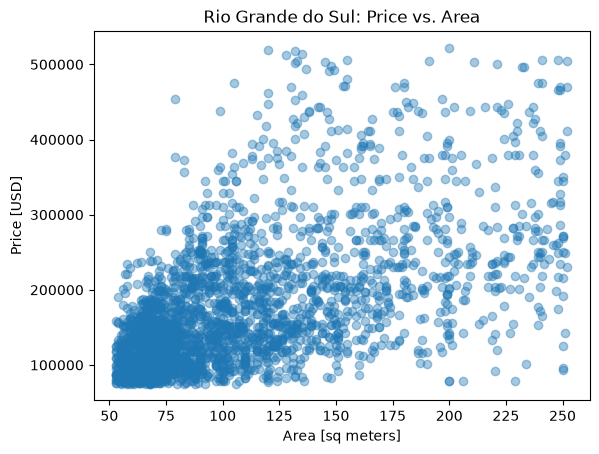

In [63]:
# Write your code here
biggest_state = homes_by_state.index[0]
df_biggest = df_south[df_south['state'] == biggest_state]

plt.scatter(df_biggest['area_m2'], df_biggest['price_usd'], alpha=0.4)
plt.xlabel('Area [sq meters]')
plt.ylabel('Price [USD]')
plt.title(biggest_state + ': Price vs. Area')
plt.show()

### Task 32 — Correlation: Brazil vs the South

Calculate the Pearson correlation between `area_m2` and `price_usd`:
* for the whole country → **`corr_brazil`**
* for the South region → **`corr_south`**

Print both values with 2 decimals.

📚 Review: Lesson 4, Exercise 9.

In [64]:
# Write your code here
corr_brazil = df['area_m2'].corr(df['price_usd'])
corr_south = df_south['area_m2'].corr(df_south['price_usd'])
print('Brazil:', round(corr_brazil, 2))
print('South:', round(corr_south, 2))

Brazil: 0.53
South: 0.53


✅ **Check your work** — run the cell below.

In [65]:
check(32)

✅ corr_brazil is correct
✅ corr_south is correct
🎉 Task 32: all checks passed!


### Task 33 — Correlation for each southern state

Create a **dictionary** **`south_states_corr`**: the keys are the names of the three southern states, and the values are the correlation coefficients between `area_m2` and `price_usd` in each state. Use a `for` loop.

The structure should look like this (example for another region — your states and numbers will differ):

```python
{'Espírito Santo': 0.63, 'Minas Gerais': 0.58, 'Rio de Janeiro': 0.46, 'São Paulo': 0.46}
```

📚 Review: Lesson 1, Section 5 (dictionaries); Lesson 4, Mini Project Step 2.

In [66]:
# Write your code here
south_states_corr = {}
for state in df_south['state'].unique():
    df_state = df_south[df_south['state'] == state]
    south_states_corr[state] = df_state['area_m2'].corr(df_state['price_usd'])

south_states_corr

{'Paraná': np.float64(0.5436659935502658),
 'Rio Grande do Sul': np.float64(0.5773267433717683),
 'Santa Catarina': np.float64(0.5068121776366781)}

✅ **Check your work** — run the cell below.

In [67]:
check(33)

✅ south_states_corr is a dictionary
✅ keys are the 3 southern states
✅ values are the correct correlation coefficients
🎉 Task 33: all checks passed!


### Task 34 — Visualize the correlations

Show `south_states_corr` as a bar chart (sorted), with a dashed horizontal line for `corr_brazil`. Set the y-axis from 0 to 1, add a legend, labels, and a title.

💡 You can turn a dictionary into a Series with `pd.Series(...)`.

📚 Review: Lesson 4, Mini Project Step 3.

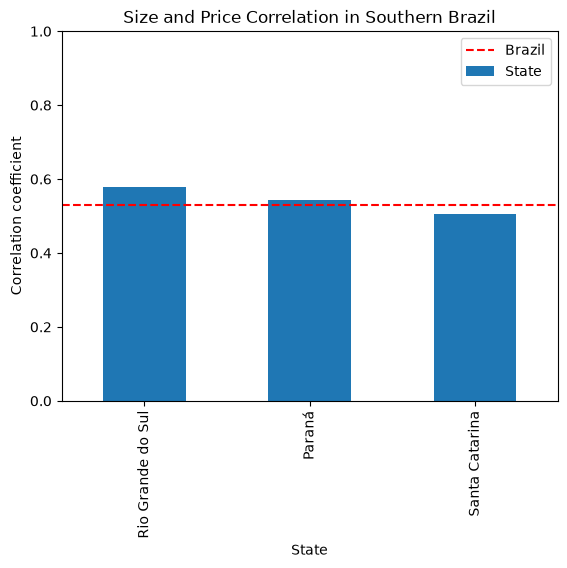

In [68]:
# Write your code here
south_corr = pd.Series(south_states_corr).sort_values(ascending=False)

south_corr.plot(kind='bar', label='State')
plt.axhline(corr_brazil, color='red', linestyle='--', label='Brazil')
plt.ylim(0, 1)
plt.xlabel('State')
plt.ylabel('Correlation coefficient')
plt.title('Size and Price Correlation in Southern Brazil')
plt.legend()
plt.show()

✍️ **Question 7:** Answer **Research Question 2**. Is there a relationship between size and price in southern Brazil? How strong is it, and does it differ between the three states? Compare with what we found for Morelos and Mexico City.

✍️ **Your answer:** 

Yes, there is a positive relationship: in southern Brazil bigger homes usually cost more. The correlation for the whole South is **0.53**, the same as for all of Brazil (**0.53**). This is a moderate relationship, not a strong one.

The three states are quite similar. **Rio Grande do Sul** has the highest value (**0.58**), then **Paraná** (**0.54**) and **Santa Catarina** (**0.51**). The difference between them is small.

In the Mexico project, Morelos had a correlation of about 0.58 and Mexico City about 0.41. So the southern states of Brazil are closer to Morelos, where size explained the price better than in Mexico City. But even in the South, size is only one part of the price, and other things like location also matter a lot

✍️ **Question 8:** A colleague says: *"The correlation proves that adding a room to a house will increase its price by a fixed amount."* Is this conclusion justified? Explain.

✍️ **Your answer:** 

No, this conclusion is not justified.

1. Correlation only shows that two things go up together. It does not prove that one causes the other. Bigger homes are often newer or in better neighborhoods, and this can also make them more expensive
2. Our data has the area in m², not the number of rooms, so we can't say anything about rooms
3. The correlation is only 0.53. This means size explains only about 28% of the differences in price (0.53^2 ~~ 0.28). Homes with the same size can have very different prices, which we can see in the scatter plot: the points make a wide cloud, not a straight line. So there is no fixed amount that one more room adds to the price

---
# Part 5 — Challenge (bonus, +10 points)

### Task 35 — Where does size matter most in Brazil?

1. Create a Series **`corr_by_state`** with the size–price correlation for **every state with at least 30 listings**, sorted from highest to lowest.
2. Plot the scatter plots of the state with the **strongest** and the **weakest** correlation side by side (same y-axis).
3. Create a DataFrame **`state_profile`** with, for each of these states: its **region**, number of **listings**, **median price per m²**, and **size–price correlation**. Sort it by median price per m².

📚 Review: Lesson 4, Mini Project.

In [69]:
# Write your code here
state_counts = df['state'].value_counts()
big_states = state_counts[state_counts >= 30].index

corr_by_state = {}
for state in big_states:
    df_state = df[df['state'] == state]
    corr_by_state[state] = df_state['area_m2'].corr(df_state['price_usd'])

corr_by_state = pd.Series(corr_by_state).sort_values(ascending=False)
corr_by_state

Pernambuco             0.754215
Goiás                  0.750686
Maranhão               0.740533
Paraíba                0.718948
Pará                   0.687916
Bahia                  0.678954
Espírito Santo         0.676370
Sergipe                0.629721
Rio Grande do Norte    0.621829
Minas Gerais           0.587676
Rio Grande do Sul      0.577327
Ceará                  0.569469
Mato Grosso            0.552470
Paraná                 0.543666
Santa Catarina         0.506812
São Paulo              0.477129
Distrito Federal       0.464197
Rio de Janeiro         0.431907
dtype: float64

✅ **Check your work** — run the cell below.

In [70]:
check(35)

✅ only states with at least 30 listings
✅ all states with at least 30 listings are included
✅ sorted from highest to lowest
🎉 Task 35: all checks passed!


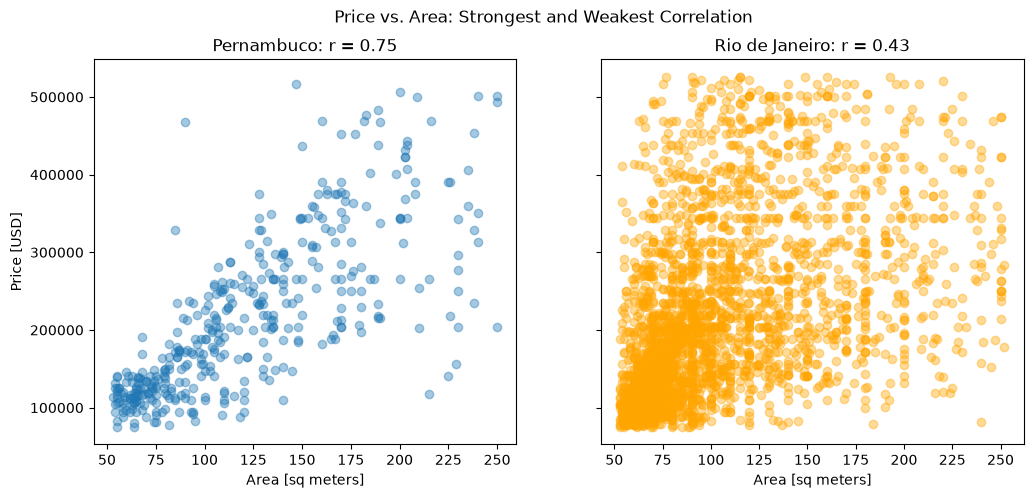

,region,listings,median_price_per_m2,size_price_corr
Rio de Janeiro,Southeast,2642,1980.99,0.43
São Paulo,Southeast,2656,1834.15,0.48
Pernambuco,Northeast,406,1809.08,0.75
Santa Catarina,South,2634,1787.01,0.51
Pará,North,299,1718.93,0.69
Ceará,Northeast,1574,1716.28,0.57
Distrito Federal,Central-West,732,1608.28,0.46
Minas Gerais,Southeast,2680,1604.42,0.59
Rio Grande do Sul,South,2643,1554.18,0.58
Bahia,Northeast,2045,1471.61,0.68


In [71]:
# Write your code here
strongest = corr_by_state.index[0]
weakest = corr_by_state.index[-1]
df_strong = df[df['state'] == strongest]
df_weak = df[df['state'] == weakest]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].scatter(df_strong['area_m2'], df_strong['price_usd'], alpha=0.4)
axes[0].set_xlabel('Area [sq meters]')
axes[0].set_ylabel('Price [USD]')
axes[0].set_title(strongest + ': r = ' + str(round(corr_by_state[strongest], 2)))

axes[1].scatter(df_weak['area_m2'], df_weak['price_usd'], alpha=0.4, color='orange')
axes[1].set_xlabel('Area [sq meters]')
axes[1].set_title(weakest + ': r = ' + str(round(corr_by_state[weakest], 2)))

plt.suptitle('Price vs. Area: Strongest and Weakest Correlation')
plt.show()

state_profile = pd.DataFrame({
    'region': df.groupby('state')['region'].first(),
    'listings': df['state'].value_counts(),
    'median_price_per_m2': df.groupby('state')['price_per_m2'].median(),
    'size_price_corr': corr_by_state,
})
state_profile = state_profile.loc[corr_by_state.index]
state_profile = state_profile.sort_values('median_price_per_m2', ascending=False)
state_profile.round(2)

✍️ **Question 9:** Do you see a pattern between how **expensive** a state is and how strongly **size** predicts price? Where would a simple formula *price = price per m² × area* work well, and where would it fail?

✍️ **Your answer:** 


Yes, there is a pattern, but it is not perfect. The most expensive states have the weakest link between size and price: **Rio de Janeiro** ($1981/m2, r = 0.43), **Sao Paulo** ($1834/m2, r = 0.48) and **Distrito Federal** ($1608/m2, r = 0.46). Many cheaper states have a much stronger link, for example **Goiás** (r = 0.75), **Maranhao** (r = 0.74) and **Paraiba** (r = 0.72). **Pernambuco** is an exception: it is expensive ($1809/m2) but has the strongest correlation (0.75). When I compared the two columns of `state_profile` for all 18 states, the correlation between them was about -0.41, so it is a moderate negative pattern

The formula *price = price per m2 × area* would work quite well in states like Pernambuco, Goias or Maranhao, where the points are close to a line. It would not work well in Rio de Janeiro or Sao Paulo. There two homes of the same size can have very different prices, probably because the neighborhood (for example near the beach or in the city center) matters more than size

---
# Part 6 — Final Report (10 points)

✍️ **Question 10 — Summary for management.** Write a short report (5–8 sentences) for the investment company's management. Include:
* the most and least expensive **regions** (with median price per m²),
* the most expensive **states**,
* what you found about **size and price** in the South,
* one **recommendation**.

Avoid technical jargon — management does not know pandas!

✍️ **Your answer:** 

We looked at about 22800 homes for sale in Brazil from 2015 and 2016. The **Southeast** is the most expensive region, with a typical price of about **$1734 per square meter**, and the **Central-West** is the cheapest, with about **$1499 per square meter**. The most expensive states are **Rio de Janeiro** ($1981 per square meter), **Sao Paulo** ($1834) and **Pernambuco** ($1809). In the South, bigger homes usually cost more, but size explains only part of the price, and this is very similar in all three southern states. Inside the South, Santa Catarina is the most expensive state ($1787 per square meter) and Parana is the cheapest ($1388). We recommend comparing places by price per square meter and not by total price, and looking at **Parana** and **Rio Grande do Sul** if the company wants a cheaper way to enter the market in the South. Before investing, the company should check newer data, because these prices are from 2015 and 2016

✍️ **Question 11 — Limitations.** Name **three limitations** of this dataset or analysis, and suggest what additional data would improve it.

✍️ **Your answer:** 


1. **Old data and one exchange rate.** The listings are from 2015 and 2016, and we used one fixed rate of 3.19 reals per dollar. Prices and the exchange rate have changed a lot since then. Newer listings and the exchange rate for each date would fix this
2. **Uneven coverage.** Some states have around 2600 listings each, but others have very few (the whole North has 309, Amapa has 1), and Acre and Roraima are not in the data at all. Several states in the raw files had exactly 3000 listings, so it looks like the data was cut at 3000 per state. A full sample for every state would make the comparison fairer
3. **Limited information about each home.** These are asking prices from listings, not final sale prices, and we only know the type, area and location. Also the data only has homes from 53 to 252 m2 and prices from about $75000 to $526000, so very small, very big or very cheap homes are missing. Real sale prices and more details, like the number of rooms, the age of the building and the neighborhood, would make the analysis much better

---
## ✅ Before You Submit

* [ ] Run **Kernel → Restart & Run All** (Colab: **Runtime → Restart and run all**) — the notebook runs from top to bottom without errors.
* [ ] All ✅ check cells show *"all checks passed"*.
* [ ] Every chart has axis labels (with units) and a title.
* [ ] All ✍️ written questions are answered in full sentences, using numbers from your results.
* [ ] Variable names match the task descriptions.

**Congratulations on completing Project 1!** 🎉 You have prepared, explored, and analyzed a real estate dataset from start to finish — the full workflow of a data analysis project.